# Heart Disease Prediction
## 1. Load data

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("heart_2020_cleaned.csv")
print(df.shape)
df.head()

(319795, 18)


,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,Race,Diabetic,PhysicalActivity,GenHealth,SleepTime,Asthma,KidneyDisease,SkinCancer
0,No,16.60,Yes,No,No,3.0,30.0,No,Female,55-59,White,Yes,Yes,Very good,5.0,Yes,No,Yes
1,No,20.34,No,No,Yes,0.0,0.0,No,Female,80 or older,White,No,Yes,Very good,7.0,No,No,No
2,No,26.58,Yes,No,No,20.0,30.0,No,Male,65-69,White,Yes,Yes,Fair,8.0,Yes,No,No
3,No,24.21,No,No,No,0.0,0.0,No,Female,75-79,White,No,No,Good,6.0,No,No,Yes
4,No,23.71,No,No,No,28.0,0.0,Yes,Female,40-44,White,No,Yes,Very good,8.0,No,No,No


## 2. Inspect
Check types, missing values, duplicates, and the target balance.

In [2]:
df.info()
print("\nMissing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nTarget balance:")
print(df["HeartDisease"].value_counts(normalize=True).round(3))

<class 'pandas.DataFrame'>
RangeIndex: 319795 entries, 0 to 319794
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   HeartDisease      319795 non-null  str    
 1   BMI               319795 non-null  float64
 2   Smoking           319795 non-null  str    
 3   AlcoholDrinking   319795 non-null  str    
 4   Stroke            319795 non-null  str    
 5   PhysicalHealth    319795 non-null  float64
 6   MentalHealth      319795 non-null  float64
 7   DiffWalking       319795 non-null  str    
 8   Sex               319795 non-null  str    
 9   AgeCategory       319795 non-null  str    
 10  Race              319795 non-null  str    
 11  Diabetic          319795 non-null  str    
 12  PhysicalActivity  319795 non-null  str    
 13  GenHealth         319795 non-null  str    
 14  SleepTime         319795 non-null  float64
 15  Asthma            319795 non-null  str    
 16  KidneyDisease     319795 non-nu

Duplicate rows: 18078

Target balance:
HeartDisease
No     0.914
Yes    0.086
Name: proportion, dtype: float64


In [3]:
# Unique values of every text column
for col in df.select_dtypes(include="object").columns:
    print(f"{col}: {df[col].unique().tolist()}")

HeartDisease: ['No', 'Yes']
Smoking: ['Yes', 'No']
AlcoholDrinking: ['No', 'Yes']
Stroke: ['No', 'Yes']
DiffWalking: ['No', 'Yes']
Sex: ['Female', 'Male']
AgeCategory: ['55-59', '80 or older', '65-69', '75-79', '40-44', '70-74', '60-64', '50-54', '45-49', '18-24', '35-39', '30-34', '25-29']
Race: ['White', 'Black', 'Asian', 'American Indian/Alaskan Native', 'Other', 'Hispanic']


Diabetic: ['Yes', 'No', 'No, borderline diabetes', 'Yes (during pregnancy)']
PhysicalActivity: ['Yes', 'No']
GenHealth: ['Very good', 'Fair', 'Good', 'Poor', 'Excellent']
Asthma: ['Yes', 'No']
KidneyDisease: ['No', 'Yes']
SkinCancer: ['Yes', 'No']


/var/folders/rl/lrv9l1_54z3dsm4_rlfz66qw0000gn/T/ipykernel_22738/3288944302.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


In [4]:
df.describe()

,BMI,PhysicalHealth,MentalHealth,SleepTime
count,319795.000000,319795.00000,319795.000000,319795.000000
mean,28.325399,3.37171,3.898366,7.097075
std,6.356100,7.95085,7.955235,1.436007
min,12.020000,0.00000,0.000000,1.000000
25%,24.030000,0.00000,0.000000,6.000000
50%,27.340000,0.00000,0.000000,7.000000
75%,31.420000,2.00000,3.000000,8.000000
max,94.850000,30.00000,30.000000,24.000000


## 3. Clean
- **Duplicates:** with only 18 mostly yes/no columns, many duplicates are probably different people who gave the same answers. Dropping them is the common choice, but it's a judgment call.
- **Outliers:** sleeping 1 or 24 hours a day, or a BMI over 80, is implausible. Clip them to a sensible range instead of dropping rows.

In [5]:
df = df.drop_duplicates().reset_index(drop=True)

df["SleepTime"] = df["SleepTime"].clip(3, 14)
df["BMI"] = df["BMI"].clip(upper=60)

print(df.shape)

(301717, 18)


## 4. Encode
- Yes/No columns → 1/0
- Ordered categories (`AgeCategory`, `GenHealth`) → ordinal integers, which keeps their order
- Unordered categories (`Race`, `Diabetic`) → one-hot columns

In [6]:
binary_cols = ["HeartDisease", "Smoking", "AlcoholDrinking", "Stroke", "DiffWalking",
               "PhysicalActivity", "Asthma", "KidneyDisease", "SkinCancer"]
for col in binary_cols:
    df[col] = df[col].map({"No": 0, "Yes": 1})

df["Sex"] = df["Sex"].map({"Female": 0, "Male": 1})

age_order = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
             "55-59", "60-64", "65-69", "70-74", "75-79", "80 or older"]
df["AgeCategory"] = df["AgeCategory"].map({a: i for i, a in enumerate(age_order)})

health_order = ["Poor", "Fair", "Good", "Very good", "Excellent"]
df["GenHealth"] = df["GenHealth"].map({h: i for i, h in enumerate(health_order)})

df = pd.get_dummies(df, columns=["Race", "Diabetic"], drop_first=True, dtype=int)

# A NaN here would mean a category was missed in a mapping above
assert df.isna().sum().sum() == 0
print(df.shape)
df.head()

(301717, 24)


,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,...,KidneyDisease,SkinCancer,Race_Asian,Race_Black,Race_Hispanic,Race_Other,Race_White,"Diabetic_No, borderline diabetes",Diabetic_Yes,Diabetic_Yes (during pregnancy)
0,0,16.60,1,0,0,3.0,30.0,0,0,7,...,0,1,0,0,0,0,1,0,1,0
1,0,20.34,0,0,1,0.0,0.0,0,0,12,...,0,0,0,0,0,0,1,0,0,0
2,0,26.58,1,0,0,20.0,30.0,0,1,9,...,0,0,0,0,0,0,1,0,1,0
3,0,24.21,0,0,0,0.0,0.0,0,0,11,...,0,1,0,0,0,0,1,0,0,0
4,0,23.71,0,0,0,28.0,0.0,1,0,4,...,0,0,0,0,0,0,1,0,0,0


## 5. Train/test split and scaling
- `stratify=y` keeps the same ~9% heart-disease rate in both splits.
- The scaler is fit on the training set **only**, so no information from the test set leaks into training.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns="HeartDisease")
y = df["HeartDisease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

num_cols = ["BMI", "PhysicalHealth", "MentalHealth", "SleepTime", "AgeCategory", "GenHealth"]
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Heart disease rate - train: %.3f, test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (241373, 23) | Test: (60344, 23)
Heart disease rate - train: 0.090, test: 0.090


## 6. Models
Both models use `class_weight="balanced"`, which weights the rare heart-disease cases more heavily. Without it, a model can reach 91% accuracy by always predicting "No". For the same reason, judge the models on **recall, F1 and ROC-AUC** rather than accuracy.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def evaluate(model, name):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, target_names=["No", "Yes"], digits=3))
    print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}\n")
    return y_pred, y_prob

### Model 1: Logistic Regression (baseline)

In [9]:
log_reg = LogisticRegression(class_weight="balanced", max_iter=1000)
log_reg.fit(X_train, y_train)
lr_pred, lr_prob = evaluate(log_reg, "Logistic Regression")

=== Logistic Regression ===
              precision    recall  f1-score   support

          No      0.970     0.740     0.840     54892
         Yes      0.228     0.771     0.351      5452

    accuracy                          0.743     60344
   macro avg      0.599     0.755     0.596     60344
weighted avg      0.903     0.743     0.796     60344

ROC-AUC: 0.832



### Model 2: Random Forest
`max_depth` and `min_samples_leaf` stop the trees from memorising the training data, and they also keep training fast.

In [10]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=20,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42,
)
rf.fit(X_train, y_train)
rf_pred, rf_prob = evaluate(rf, "Random Forest")

=== Random Forest ===
              precision    recall  f1-score   support

          No      0.973     0.719     0.827     54892
         Yes      0.220     0.799     0.345      5452

    accuracy                          0.726     60344
   macro avg      0.597     0.759     0.586     60344
weighted avg      0.905     0.726     0.783     60344

ROC-AUC: 0.833



## 7. Compare

In [11]:
from sklearn.metrics import recall_score, precision_score, f1_score, accuracy_score

results = pd.DataFrame({
    name: {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    }
    for name, pred, prob in [("Logistic Regression", lr_pred, lr_prob),
                             ("Random Forest", rf_pred, rf_prob)]
}).round(3)
results

,Logistic Regression,Random Forest
Accuracy,0.743,0.726
Precision,0.228,0.220
Recall,0.771,0.799
F1,0.351,0.345
ROC-AUC,0.832,0.833


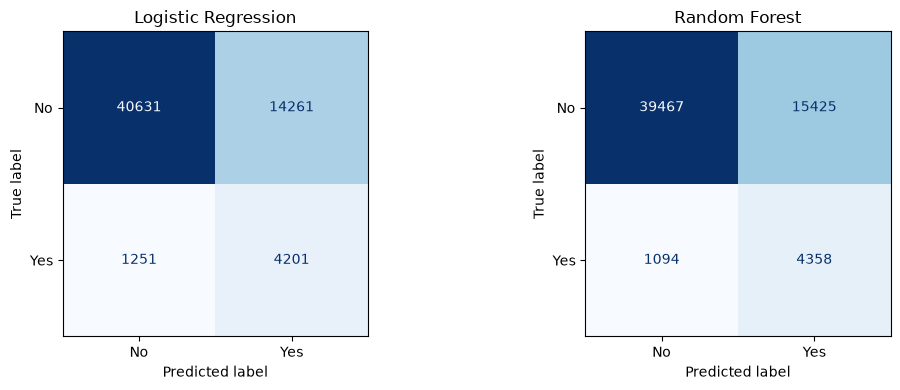

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, pred) in zip(axes, [("Logistic Regression", lr_pred), ("Random Forest", rf_pred)]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No", "Yes"],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

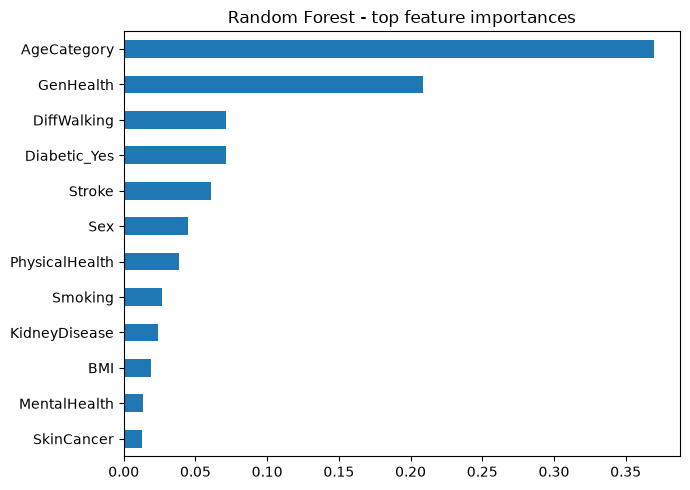

In [13]:
# Which features the random forest relied on most
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()
importances.tail(12).plot.barh(figsize=(7, 5), title="Random Forest - top feature importances")
plt.tight_layout()
plt.show()